In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
import math

#### Loading, Cleaning and pre-processing data

In [4]:
df = pd.read_csv("training.csv") # Reads csv file, make dataframe and stores in df var.

In [5]:
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [6]:
df.shape

(4600, 18)

In [7]:
df.info() # dtypes + har column ke non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float64(4), int6

In [8]:
print(df.isna().sum()) # missing values in each column(fir uska sum)

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64


In [9]:
print(df.duplicated().sum())  # duplicate rows- fully repeated ones!

0


In [10]:
print(df.describe().T) # min / max / quartiles/ count- This is done by describe. .T converts columns to rows for easy-reading.

                count           mean            std     min        25%  \
price          4600.0  551962.988473  563834.702547     0.0  322875.00   
bedrooms       4600.0       3.400870       0.908848     0.0       3.00   
bathrooms      4600.0       2.160815       0.783781     0.0       1.75   
sqft_living    4600.0    2139.346957     963.206916   370.0    1460.00   
sqft_lot       4600.0   14852.516087   35884.436145   638.0    5000.75   
floors         4600.0       1.512065       0.538288     1.0       1.00   
waterfront     4600.0       0.007174       0.084404     0.0       0.00   
view           4600.0       0.240652       0.778405     0.0       0.00   
condition      4600.0       3.451739       0.677230     1.0       3.00   
sqft_above     4600.0    1827.265435     862.168977   370.0    1190.00   
sqft_basement  4600.0     312.081522     464.137228     0.0       0.00   
yr_built       4600.0    1970.786304      29.731848  1900.0    1951.00   
yr_renovated   4600.0     808.608261  

In [11]:
print((df.select_dtypes("number") == 0).sum())   # Numeric column chunega fir dekhega kitne cell uss column ke 0 hai(True values). And then adds them

price              49
bedrooms            2
bathrooms           2
sqft_living         0
sqft_lot            0
floors              0
waterfront       4567
view             4140
condition           0
sqft_above          0
sqft_basement    2745
yr_built            0
yr_renovated     2735
dtype: int64


In [12]:
df = df.loc[(df["price"]>0) & (df["bedrooms"]>0) & (df["bathrooms"]>0)]

In [13]:
len(df)

4549

In [14]:
print((df.select_dtypes("number") == 0).sum())

price               0
bedrooms            0
bathrooms           0
sqft_living         0
sqft_lot            0
floors              0
waterfront       4519
view             4102
condition           0
sqft_above          0
sqft_basement    2716
yr_built            0
yr_renovated     2706
dtype: int64


In [15]:
df.shape

(4549, 18)

#### Model training

In [16]:
cols = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront", "view", "condition"]
X = df[cols] # Jo columns features banenge
y = np.log(df.price).to_numpy() # Taken log of all real prices for easy computation also converted into numpy array.

In [17]:
print(X.shape, y.shape) 

(4549, 8) (4549,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42) # random_state ensures data is split into the exact same training and testing sets every time.
print(X_train.shape, X_test.shape)

(3639, 8) (910, 8)


In [19]:
def Z_normalization(X):
# X is a matrix of shape (m,n)--> m examples and n features. Remember n = 8 not 18.
    mu = np.mean(X, axis = 0) # It calculate mean of each feature i.e. every column so mu have (n,) shape.

    sigma = np.std(X, axis = 0) # Similar to mean.(n,)

    X_train_norm = (X - mu)/sigma # It's shape is (m,n)

    return (X_train_norm,mu,sigma) 

In [20]:
X_train_norm , mu, sigma = Z_normalization(X_train)

mu,sigma = mu.to_numpy(), sigma.to_numpy()
print(f"X_mu = {mu} \nX_sigma = {sigma}")
# print(X_train_norm)

X_mu = [3.38059907e+00 2.14976642e+00 2.11985161e+03 1.45547406e+04
 1.51112943e+00 6.59521847e-03 2.29183842e-01 3.44929926e+00] 
X_sigma = [8.91761057e-01 7.62052071e-01 9.32414214e+02 3.64736915e+04
 5.37619982e-01 8.09427054e-02 7.63062608e-01 6.76702907e-01]


In [21]:
X_test_norm = (X_test - mu)/sigma # Mu and sigma are never taken out of test data only used of train data. Because test is unknown dataset and we can't use it's info.

In [22]:
X_train_norm = X_train_norm.to_numpy()
# print(X_train_norm)

In [23]:
def cost_fxn(X,y,w,b):
    m = len(X) # No. of egs.
    J_wb = 0
    for i in range(m):
        f_wb = np.dot(X[i], w) + b
        cost = (f_wb - y[i]) ** 2
        J_wb += cost

    J_wb = J_wb/(2*m)

    return J_wb

In [24]:
n = X_train_norm.shape[1]
w_init = np.zeros(n)
b_init = 0
cost = cost_fxn(X_train_norm, y_train, w_init, b_init)
print(f'Initial cost: {cost}')

Initial cost: 85.47236259821631


In [25]:
def compute_gradient(X,y,w,b):
    m,n = X.shape
    dj_db = 0
    dj_dw = np.zeros((n,)) 

    for i in range(m):
        f_wb = np.dot(X[i],w) + b
        err = f_wb - y[i]

        for j in range(n):
            dj_dw[j] = dj_dw[j] + err*X[i,j] 
        dj_db = dj_db + err
    dj_dw = dj_dw/m
    dj_db = dj_db/m

    return dj_db, dj_dw

In [26]:
#Compute and display gradient 
tmp_dj_db, tmp_dj_dw = compute_gradient(X_train_norm, y_train, w_init, b_init)
print(f'dj_db at initial w,b: {tmp_dj_db}')
print(f'dj_dw at initial w,b: \n {tmp_dj_dw}')

dj_db at initial w,b: -13.063425455914995
dj_dw at initial w,b: 
 [-0.1917097  -0.29526572 -0.36152994 -0.04428103 -0.1671464  -0.07317572
 -0.16979633 -0.03496514]


In [27]:
# An array to store cost J and w's for each iteration.
def gradient_descent(X_train,y_train,w_in,b_in,alpha,num_iters,cost_fxn,compute_gradient):
    J_wb = []
    w = w_in.copy()
    b = b_in
    for i in range(num_iters):
        dj_db, dj_dw = compute_gradient(X_train, y_train, w, b) 
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
    
        # Save cost J at each iteration
        if i<100000: # Prevents resource exhaustion. As 100000 hua to itna lamba array nhi bnega.
            J_wb.append(cost_fxn(X_train, y_train,w,b))

            # Prints at every 10% iterations in loop
            if i % math.ceil(num_iters/10) == 0: # math.ceil is imp. as if num_iters = 95 then w/o it i%9.5 is calculated and not i%10. So 10% wali iteration nhi milegi as i in integer.
                print(f"Iteration {i}: Cost {J_wb[-1]:.4f}")

    return J_wb, w, b

In [28]:
w_initial = w_init
b_initial = 0.
alpha = 0.05
iterations = 2000
J_history, w_final, b_final = gradient_descent(X_train_norm,y_train,w_initial,b_initial,alpha,iterations,cost_fxn,compute_gradient)
print(f"b,w found by gradient descent: {b_final:0.2f},{w_final} ")

Iteration 0: Cost 77.1380
Iteration 200: Cost 0.0735
Iteration 400: Cost 0.0734
Iteration 600: Cost 0.0734
Iteration 800: Cost 0.0734
Iteration 1000: Cost 0.0734
Iteration 1200: Cost 0.0734
Iteration 1400: Cost 0.0734
Iteration 1600: Cost 0.0734
Iteration 1800: Cost 0.0734
b,w found by gradient descent: 13.06,[-0.04246661  0.04515759  0.32198846 -0.02385645  0.06097202  0.00874935
  0.06362654  0.07547092] 


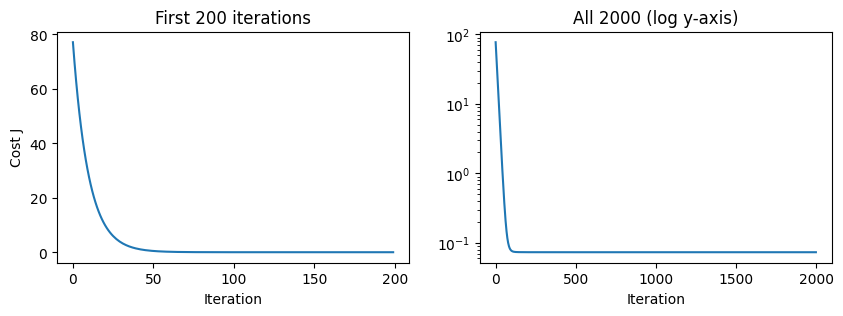

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(J_history[:200])
ax[0].set_title("First 200 iterations")
ax[0].set_xlabel("Iteration"); ax[0].set_ylabel("Cost J")

ax[1].plot(J_history)
ax[1].set_yscale("log")
ax[1].set_title("All 2000 (log y-axis)")
ax[1].set_xlabel("Iteration")
plt.show()

Left plot(for 200) reduces rapidly in 50 iterations. But in right one after approx 200 iteration cost has no change means the point of global min is found out. After 200 iteration dj_dw and dj_db become so small that no change is visible in values of w,b means min point is found out.
Also since cost is convex so there's only one Global minimum.

Iteration 0: Cost 83.7712
Iteration 10: Cost 68.5189
Iteration 20: Cost 56.0491
Iteration 30: Cost 45.8530
Iteration 40: Cost 37.5153
Iteration 50: Cost 30.6968
Iteration 60: Cost 25.1204
Iteration 70: Cost 20.5599
Iteration 80: Cost 16.8299
Iteration 90: Cost 13.7792
Iteration 0: Cost 77.1380
Iteration 10: Cost 27.6904
Iteration 20: Cost 9.9756
Iteration 30: Cost 3.6251
Iteration 40: Cost 1.3481
Iteration 50: Cost 0.5315
Iteration 60: Cost 0.2385
Iteration 70: Cost 0.1333
Iteration 80: Cost 0.0954
Iteration 90: Cost 0.0817
Iteration 0: Cost 69.2324
Iteration 10: Cost 8.4816
Iteration 20: Cost 1.0978
Iteration 30: Cost 0.1992
Iteration 40: Cost 0.0895
Iteration 50: Cost 0.0758
Iteration 60: Cost 0.0740
Iteration 70: Cost 0.0737
Iteration 80: Cost 0.0736
Iteration 90: Cost 0.0735
Iteration 0: Cost 21.4189
Iteration 10: Cost 0.0738
Iteration 20: Cost 0.0734
Iteration 30: Cost 0.0734
Iteration 40: Cost 0.0734
Iteration 50: Cost 0.0734
Iteration 60: Cost 0.0734
Iteration 70: Cost 0.0734
It

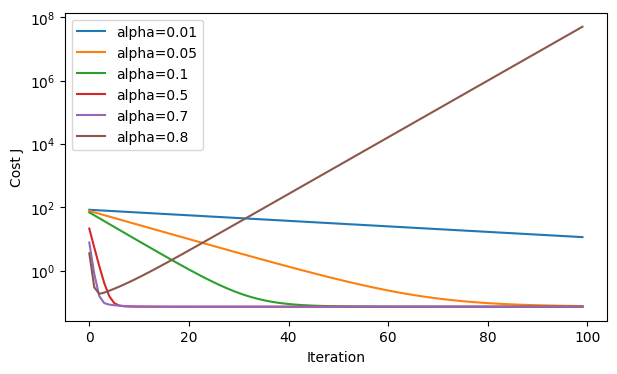

In [30]:
alphas = [0.01, 0.05, 0.1, 0.5, 0.7, 0.8]
plt.figure(figsize=(7, 4))
for a in alphas:
    J_hist, _, _ = gradient_descent(X_train_norm, y_train, w_initial, 0., a, 100, cost_fxn, compute_gradient)
    plt.plot(J_hist, label=f"alpha={a}")
plt.yscale("log")
plt.xlabel("Iteration"); plt.ylabel("Cost J"); plt.legend()
plt.show()

Here- Theoretical limit 2/λmax ≈ 0.759 so after 0.7 i.e. at 0.8 cost drastically changes because of very large steps. Instead of decreasing it's increasing as w - alpha * dj_dw here Gradient descent will diverge. Slope becomes extreme negative-positive as on other side it becomes more steep.

In [31]:
X_test_norm = X_test_norm.to_numpy()

#### What's RMSE? Why we use it?
Root Mean Squared Error = sqrt(mean((pred − actual)²)). It tells model's typical mistake is how much big and in same units as y. For eg. y is in log-price so 0.394 means prediction is 1.5 times of typical price.(e^0.394 ≈ 1.48, yaani ~+48% / −33%).

It's taken different from cost because cost formula is derivative-friendly(J = MSE/2). By taking sqrt(2J) units are like again y and comparison between train vs test, or model vs baseline becomes easy. Train 0.383 and test 0.394 are close, so no overfitting.

In [45]:
RMSE_train = math.sqrt(2 * J_history[-1]) # Training set ki RMSE value
print(f'RMSE value for training set : {RMSE_train}')

RMSE value for training set : 0.38317405013936495


In [33]:
n = X_test_norm.shape[1]
w = w_final
b = b_final
J_wb_test = cost_fxn(X_test_norm, y_test, w, b) # This is cost not MSE. MSE = 2* J_wb_test
print(f'Cost for test set : {J_wb_test}')

Cost for test set : 0.07761518264117238


In [34]:
RMSE_test = math.sqrt(2 * J_wb_test) # Testing set ki RMSE value
print(f'RMSE value for test set : {RMSE_test}')

RMSE value for test set : 0.39399284927818773


#### What's Baseline and why we take w= 0 and b = np.mean(y_train)

w = 0 in f = w·x + b = b, means model ignores features and predicts a number for every house.
Now, acc. to squared error a good constant number is, that's why b = mean.
For e.g. 0.5522 → 0.3940 means features have reduced typical error by ~29%. If model is near baseline then chosen features are not good or have many bugs in them.

Interesting link: R² = 1 − (model MSE / baseline MSE) = 1 − (0.394² / 0.5522²) ≈ 0.491, same R² which sklearn gives.

In [35]:
# Baseline
n = X_train_norm.shape[1]
w = np.zeros(n)
b = np.mean(y_train, axis = 0) # Seekhega train se hi
J_test_baseline = cost_fxn(X_test_norm, y_test, w, b) # Testing mein X_test_norm hoga. Sabse dumb model testing ke data pr. Training ka thori vo to alg dataset h.
print(f'Baseline Cost for test set : {J_test_baseline}')

Baseline Cost for test set : 0.15248371568246522


In [36]:
RMSE_baseline = math.sqrt(2 * J_test_baseline)
print(f'RMSE value for baseline test set : {RMSE_baseline}')

RMSE value for baseline test set : 0.5522385638154316


In [47]:
print(f'RMSE_baseline to RMSE_test= {RMSE_baseline},{RMSE_test}')
print(f"See it reduces RMSE by(if features taken) {((RMSE_baseline - RMSE_test) / RMSE_baseline) * 100:.4f}%")

RMSE_baseline to RMSE_test= 0.5522385638154316,0.39399284927818773
See it reduces RMSE by(if features taken) 28.6553%


#### What's R² and it's use?

R² (R-squared)- A no. which tells that how much times model has reduced baseline's squared error(MSE). 0 means as bad as baseline, 1 means perfect, and negative means bad than baseline. Our 0.491 means model removed baseline's ~49% squared.

###### RMSE² = MSE

In [38]:
MSE_baseline = 2*J_test_baseline # OR (RMSE_baseline)**2
MSE_test = 2*J_wb_test # OR (RMSE_test)**2
R_sq = 1 - (MSE_test/MSE_baseline)
print(f'R² of test is {R_sq}')
print(f"This {R_sq*100:.2f}% it's MSE error reduced if features are taken")

R² of test is 0.49099362975388394
This 49.10% it's MSE error reduced if features are taken


## Using scikit-learn

In [39]:
linear_model = LinearRegression()
#X must be a 2-D Matrix
c = linear_model.fit(X_train_norm, y_train) 

#### View parameters
The w and b parameters are referred to as 'coefficients' and 'intercept' in scikit-learn.

In [40]:
b_sk = linear_model.intercept_ 
w_sk = linear_model.coef_
print("sklearn's w:", w_sk, "| b:", round(b_sk, 4)) # With sklearn
print("scratch w:", w_final, "| b:", round(b_final, 4)) # Without it, by above Gradient descent

sklearn's w: [-0.04246661  0.04515759  0.32198846 -0.02385645  0.06097202  0.00874935
  0.06362654  0.07547092] | b: 13.0634
scratch w: [-0.04246661  0.04515759  0.32198846 -0.02385645  0.06097202  0.00874935
  0.06362654  0.07547092] | b: 13.0634


#### Np.isclose and Np.allclose
Use np.isclose- when you want to identify which values match approximately it returns array of Boolean values for array inputs.
Use np.allclose- when you want to check whether two entire arrays are approximately equal it returns a single Boolean: True only when all elements are close.

In [41]:
print("w match:", np.allclose(w_sk, w_final), "| b match:", np.isclose(b_sk, b_final)) # ALl values matched

w match: True | b match: True


In [42]:
# Predictions: sklearn vs manual (X * w + b) vs actual
pred_sk = linear_model.predict(X_train_norm)
pred_manual = X_train_norm @ w_final + b_final
print("first 4 sklearn:", pred_sk[:4])
print("first 4 manual :", pred_manual[:4])
print("first 4 actual :", y_train[:4])
print("preds match:", np.allclose(pred_sk, pred_manual))

first 4 sklearn: [13.01992981 13.18286626 13.21994619 12.98505661]
first 4 manual : [13.01992981 13.18286626 13.21994619 12.98505661]
first 4 actual : [13.36138028 13.65299163 12.4302157  12.80490915]
preds match: True


In [43]:
# Test metrics
pred_test_sk = linear_model.predict(X_test_norm)
mse = mean_squared_error(y_test, pred_test_sk) # full MSE, J (cost) nahi
print(f"MSE = {mse:.4f}")  
print(f"RMSE = {np.sqrt(mse):.4f}")  
print(f"R² = {r2_score(y_test, pred_test_sk):.4f}")

MSE = 0.1552
RMSE = 0.3940
R² = 0.4909


In [44]:
# Ek ghar ka price. Order: bedrooms, bathrooms, sqft_living, sqft_lot, floors, waterfront, view, condition

x_house = np.array([[3, 2, 1800, 5000, 1, 0, 0, 3]])
x_house_norm = (x_house - mu) / sigma # train wale mu, sigma (arrays)
pred_log_sk = linear_model.predict(x_house_norm)[0] # log-price
print(f"Predicted price: ${np.exp(pred_log_sk):,.0f}") # Taken exponential as training of model is done w.r.t log(y) values

Predicted price: $377,215
